In [73]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import sklearn.tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_fscore_support

SEED = 6021
DATA = Path("..") / "data" / "processed"

OUTCOME_NAMES = {1: "died", 2: "passed chamber", 3: "law"}

pd.set_option("display.max_columns", 50)

In [74]:
df = pd.read_csv(DATA / "model_ready_billz.csv")

In [ ]:
TARGET = "outcome"

NUM = [
    "n_original_cosponsors", "days_left_in_congress",
    "nominate_dim1", "nominate_dim2", "abs_nominate_dim1",
    "seniority", "vote_share", "delegation_size", "lagged_les",
    "dist_from_median", "n_original_bipartisan"
]

CAT = ["type", "origin_chamber", "sponsor_party", "policy_area"]

BIN = [
    "commemorative", "sponsor_majority", "freshman", "chair", "subchair",
    "power_cmte", "maj_leader", "min_leader", "state_leg", "lagged_les_missing",
    "leadership_number", "has_cosponsors", "early_intro", "is_bipartisan"
]

# identifiers
DROP = [
    "bill_id", "congress", "introduced_date", "title",
    "sponsor_bioguide_id", "sponsor_state", "icpsr"
]

FEATURES = NUM + CAT + BIN


In [76]:
TRAIN_CONGRESSES = list(range(109, 118))
TEST_CONGRESS = 118

train = df[df['congress'].isin(TRAIN_CONGRESSES).reset_index(drop=True)]
test = df[df['congress'] == TEST_CONGRESS].reset_index(drop=True)

X_train, y_train = train[FEATURES], train[TARGET]
groups_train = train['sponsor_bioguide_id']

X_test, y_test = test[FEATURES], test[TARGET]

print("train:", X_train.shape, "| test:", X_test.shape)
print("sponsors in train:", groups_train.nunique())

train: (101684, 23) | test: (16495, 23)
sponsors in train: 1204


# cv setup

In [77]:
N_SPLITS = 5
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
# check that every validation fold has enough of each class (especialy 3 = law)
fold_counts = pd.DataFrame(
    {f"fold {i}": y_train.iloc[val].value_counts().sort_index()
     for i, (_, val) in enumerate(cv.split(X_train, y_train, groups_train))}
).rename(index=OUTCOME_NAMES)
fold_counts

,fold 0,fold 1,fold 2,fold 3,fold 4
outcome,,,,,
died,18599,18596,18596,18601,18598
passed chamber,1075,1075,1076,1075,1076
law,662,667,665,661,662


# evaluation function

In [78]:
SCORING = {"f1_macro": "f1_macro", "bal_acc": "balanced_accuracy", "acc": "accuracy"}

results = []

def evaluate(name, model, prep, notes=""): # clone to give each model it's own copy of the pipeline
    pipe = Pipeline([("prep", clone(prep)), ("clf", model)])
    scores = cross_validate( # fit clone on four folds, score on 5th
        pipe, X_train, y_train, groups=groups_train,
        cv=cv, scoring=SCORING, n_jobs=-1,
        return_train_score=True, # -1 runs jobs in parallel across CPU cores
    )
    # scores will be a dict of arrays containing fit time, score time, test_f1, test_bal_acc, and acc

    row = {"model": name, "notes": notes}

    for metric in SCORING:
        s = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = round(s.mean(), 4)
        row[f"{metric}_std"] = round(s.std(), 4)
    row['fit_sec'] = round(scores['fit_time'].mean(), 2)

    results[:] = [r for r in results if r["model"] != name] # results[:] replaces contents of existing global results list in place
    # list comprehension removes any row with same name
    results.append(row)
    return pipe

def show_results(sort_by="f1_macro_mean"):
    # turn list of dicts into dataframe
    return pd.DataFrame(results).sort_values(sort_by, ascending=False).reset_index(drop=True)

# diagnostic function for confusion matrices and forest predictions

In [79]:
prep_tree = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), CAT),
    ("rest", "passthrough", NUM + BIN)
])

# single shallow decision tree

In [45]:
single_tree = evaluate("tree_d5_bal", sklearn.tree.DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEED), prep=prep_tree)

In [65]:
show_results()


,model,notes,f1_macro_mean,f1_macro_std,bal_acc_mean,bal_acc_std,acc_mean,acc_std,fit_sec
0,rf_leaf5,min_samples_leaf=5,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.16
1,rf_max_depth: None,max_depth=None,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.48
2,rf_max_features: sqrt,max_features=sqrt,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.98
3,rf_n_estimators: 400,n_estimators=400,0.4804,0.0033,0.5319,0.0122,0.8149,0.0084,35.26
4,rf_n_estimators: 350,n_estimators=350,0.4804,0.0033,0.5315,0.0114,0.8149,0.0083,30.59
5,rf_n_estimators: 450,n_estimators=450,0.4797,0.0039,0.5315,0.0127,0.8145,0.0078,40.08
6,rf_n_estimators: 300,n_estimators=300,0.4797,0.0037,0.5311,0.0115,0.8144,0.0075,26.98
7,rf_n_estimators: 500,n_estimators=500,0.4795,0.0042,0.5313,0.0123,0.8142,0.0080,43.97
8,rf_max_depth: 20,max_depth=20,0.4788,0.0047,0.5305,0.0133,0.8130,0.0071,17.41
9,rf_max_features: 0.3,max_features=0.3,0.4744,0.0102,0.4505,0.0120,0.8984,0.0029,36.08


## tree below separate fit just for picture: trained on all of 109-117 congress

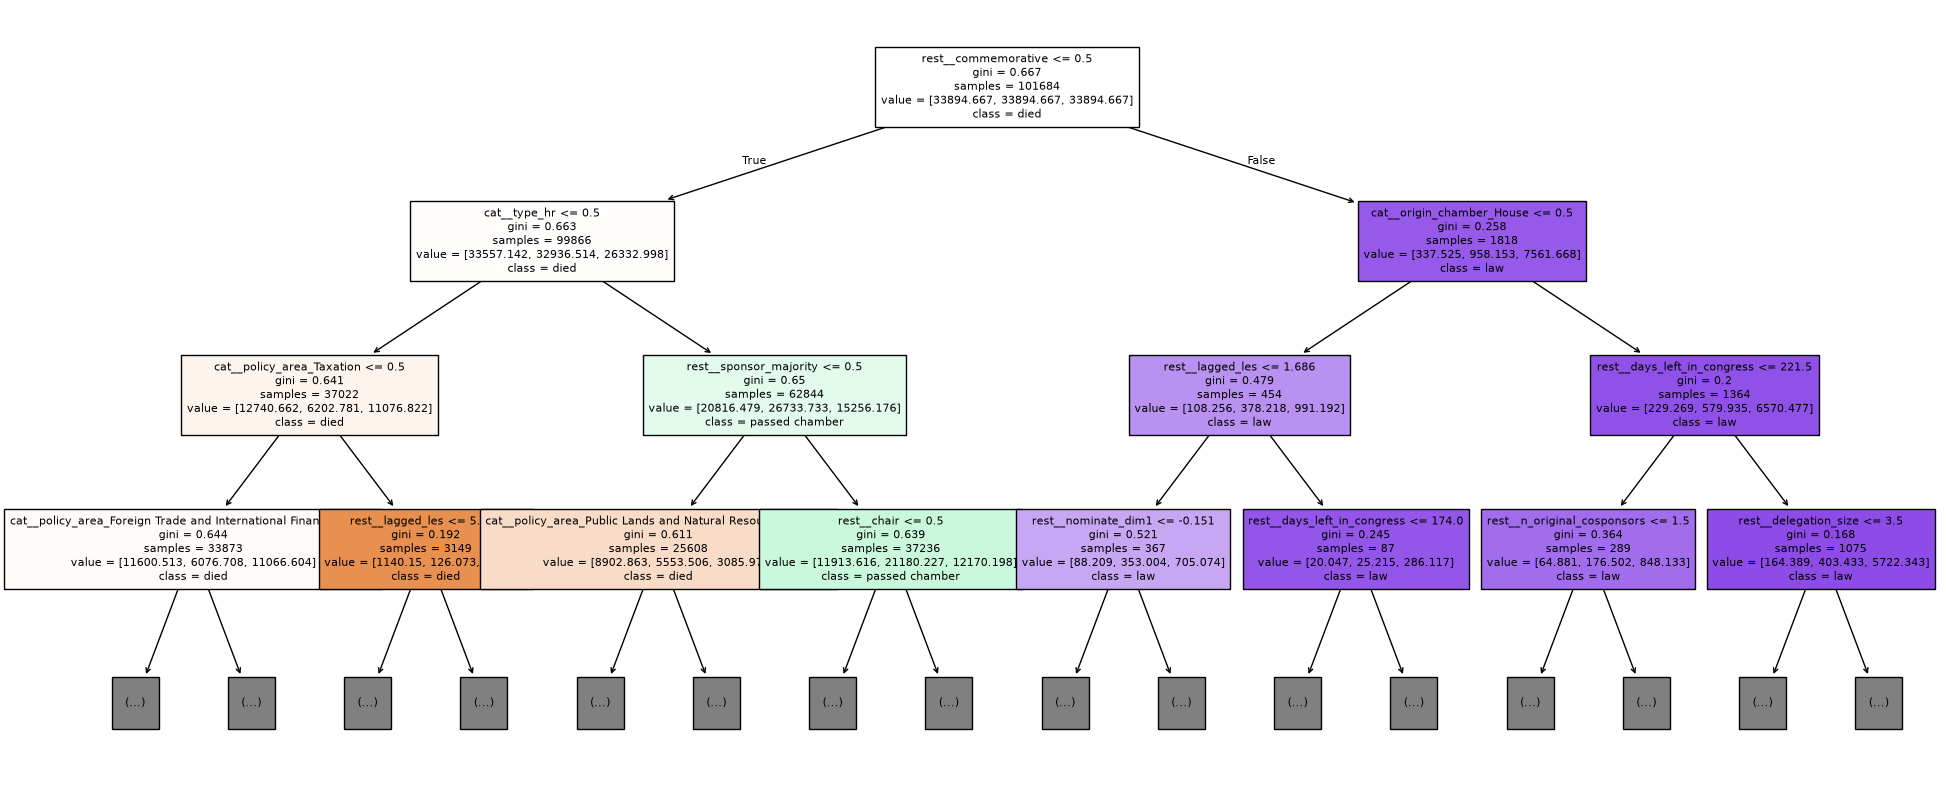

In [47]:
single_tree.fit(X_train, y_train)
tree_model = single_tree.named_steps["clf"] # DecisionTreeClassifier 
feat_names = single_tree.named_steps['prep'].get_feature_names_out() # get the names after one-hot-encoding

fig, ax = plt.subplots(figsize=(24,10))
sklearn.tree.plot_tree(tree_model, feature_names=feat_names, 
                       class_names=[OUTCOME_NAMES[c] for c in tree_model.classes_],
                       filled=True, max_depth=3, fontsize=8, ax=ax)

plt.show()

# default random forest with class wweights

In [48]:
random_forest_default = evaluate("rf_default_bal", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                                          n_jobs=-1, random_state=SEED), prep=prep_tree)

In [49]:
show_results()

,model,notes,f1_macro_mean,f1_macro_std,bal_acc_mean,bal_acc_std,acc_mean,acc_std,fit_sec
0,rf_default_bal,,0.4510,0.0063,0.4188,0.0066,0.9129,0.0012,8.99
1,tree_d5_bal,,0.3676,0.0098,0.5204,0.0130,0.6056,0.0351,0.94


# checking most important hyperparameters one at a time before doing gridsearch or randomized search or whatever

In [50]:
for leaf in [1, 5, 20, 50]:
    evaluate(f"rf_leaf{leaf}", RandomForestClassifier(n_estimators=200, min_samples_leaf=leaf, 
                                                      class_weight="balanced_subsample", random_state=SEED),
                                                      prep=prep_tree, notes=f"min_samples_leaf={leaf}")

In [51]:
show_results()

,model,notes,f1_macro_mean,f1_macro_std,bal_acc_mean,bal_acc_std,acc_mean,acc_std,fit_sec
0,rf_leaf5,min_samples_leaf=5,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.16
1,rf_leaf20,min_samples_leaf=20,0.4527,0.0028,0.5591,0.0089,0.7659,0.0093,17.21
2,rf_default_bal,,0.4510,0.0063,0.4188,0.0066,0.9129,0.0012,8.99
3,rf_leaf50,min_samples_leaf=50,0.4159,0.0045,0.5741,0.0078,0.6901,0.0111,16.18
4,rf_leaf1,min_samples_leaf=1,0.3903,0.0076,0.3750,0.0055,0.9173,0.0003,22.20
5,tree_d5_bal,,0.3676,0.0098,0.5204,0.0130,0.6056,0.0351,0.94


appears as though 5 samples per leaf produces best results - definitely not 50 leaves or greater and definitely not less than 5.

In [52]:
for max_features in ["sqrt", 0.3, 0.5]:
    evaluate(f"rf_max_features: {max_features}", RandomForestClassifier(n_estimators=200, min_samples_leaf=5, max_features=max_features,
                                                                        class_weight="balanced_subsample", random_state=SEED),
                                                                        prep=prep_tree, notes=f"max_features={max_features}")

In [53]:
show_results()

,model,notes,f1_macro_mean,f1_macro_std,bal_acc_mean,bal_acc_std,acc_mean,acc_std,fit_sec
0,rf_leaf5,min_samples_leaf=5,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.16
1,rf_max_features: sqrt,max_features=sqrt,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.98
2,rf_max_features: 0.3,max_features=0.3,0.4744,0.0102,0.4505,0.0120,0.8984,0.0029,36.08
3,rf_max_features: 0.5,max_features=0.5,0.4715,0.0105,0.4446,0.0116,0.9020,0.0015,58.25
4,rf_leaf20,min_samples_leaf=20,0.4527,0.0028,0.5591,0.0089,0.7659,0.0093,17.21
5,rf_default_bal,,0.4510,0.0063,0.4188,0.0066,0.9129,0.0012,8.99
6,rf_leaf50,min_samples_leaf=50,0.4159,0.0045,0.5741,0.0078,0.6901,0.0111,16.18
7,rf_leaf1,min_samples_leaf=1,0.3903,0.0076,0.3750,0.0055,0.9173,0.0003,22.20
8,tree_d5_bal,,0.3676,0.0098,0.5204,0.0130,0.6056,0.0351,0.94


default sqrt parameter for max features seems to work best

In [54]:
for max_depth in [None, 10, 20]:
    evaluate(f"rf_max_depth: {max_depth}", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                                  max_depth=max_depth,
                                                                  class_weight="balanced_subsample",
                                                                  random_state=SEED),
                                                                  prep=prep_tree, notes=f"max_depth={max_depth}")

In [55]:
show_results()

,model,notes,f1_macro_mean,f1_macro_std,bal_acc_mean,bal_acc_std,acc_mean,acc_std,fit_sec
0,rf_leaf5,min_samples_leaf=5,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.16
1,rf_max_features: sqrt,max_features=sqrt,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.98
2,rf_max_depth: None,max_depth=None,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.48
3,rf_max_depth: 20,max_depth=20,0.4788,0.0047,0.5305,0.0133,0.8130,0.0071,17.41
4,rf_max_features: 0.3,max_features=0.3,0.4744,0.0102,0.4505,0.0120,0.8984,0.0029,36.08
5,rf_max_features: 0.5,max_features=0.5,0.4715,0.0105,0.4446,0.0116,0.9020,0.0015,58.25
6,rf_leaf20,min_samples_leaf=20,0.4527,0.0028,0.5591,0.0089,0.7659,0.0093,17.21
7,rf_default_bal,,0.4510,0.0063,0.4188,0.0066,0.9129,0.0012,8.99
8,rf_leaf50,min_samples_leaf=50,0.4159,0.0045,0.5741,0.0078,0.6901,0.0111,16.18
9,rf_max_depth: 10,max_depth=10,0.3979,0.0046,0.5664,0.0084,0.6433,0.0137,13.03


max depth of 20 or above seems best

In [56]:
for n_estimators in [300, 350, 400, 450, 500]:
    evaluate(f"rf_n_estimators: {n_estimators}", RandomForestClassifier(n_estimators=n_estimators, min_samples_leaf=5, 
                                                                        max_depth=20, 
                                                                        class_weight="balanced_subsample",
                                                                        random_state=SEED),
                                                                        prep=prep_tree, notes=f"n_estimators={n_estimators}")

In [57]:
show_results()

,model,notes,f1_macro_mean,f1_macro_std,bal_acc_mean,bal_acc_std,acc_mean,acc_std,fit_sec
0,rf_leaf5,min_samples_leaf=5,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.16
1,rf_max_depth: None,max_depth=None,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.48
2,rf_max_features: sqrt,max_features=sqrt,0.4926,0.0086,0.4858,0.0153,0.8808,0.0052,19.98
3,rf_n_estimators: 400,n_estimators=400,0.4804,0.0033,0.5319,0.0122,0.8149,0.0084,35.26
4,rf_n_estimators: 350,n_estimators=350,0.4804,0.0033,0.5315,0.0114,0.8149,0.0083,30.59
5,rf_n_estimators: 450,n_estimators=450,0.4797,0.0039,0.5315,0.0127,0.8145,0.0078,40.08
6,rf_n_estimators: 300,n_estimators=300,0.4797,0.0037,0.5311,0.0115,0.8144,0.0075,26.98
7,rf_n_estimators: 500,n_estimators=500,0.4795,0.0042,0.5313,0.0123,0.8142,0.0080,43.97
8,rf_max_depth: 20,max_depth=20,0.4788,0.0047,0.5305,0.0133,0.8130,0.0071,17.41
9,rf_max_features: 0.3,max_features=0.3,0.4744,0.0102,0.4505,0.0120,0.8984,0.0029,36.08


best amount of estimators likely somewhere between 400 and 450

# Going to try random search

In [69]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import average_precision_score

In [67]:
# custom scoring function: avg precision for law (how well model ranks bills that became law)
def ap_law(est, X, y):
    proba = est.predict_proba(X)
    return average_precision_score(y == 3, proba[:, list(est.classes_).index(3)])

In [70]:
# this will take like 3 hrs probably
rf_pipe = Pipeline([
    ("prep", prep_tree),
    ("clf", RandomForestClassifier(n_estimators=400,
                                   class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))
])


param_grid = {
    "clf__min_samples_leaf": [1, 2, 3, 5, 8, 12, 20],
    "clf__max_features": ["sqrt", 0.2, 0.3, 0.5],
    "clf__max_depth": [None, 15, 25, 40],
    "clf__class_weight": ["balanced_subsample", None]
}

search = GridSearchCV(
    rf_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring={"f1_macro": "f1_macro", "bal_acc": "balanced_accuracy", "ap_law": ap_law},
    refit="f1_macro",
    return_train_score=True,
    verbose=2
)
search.fit(X_train, y_train, groups=groups_train)


#SAVE!
import joblib
pd.DataFrame(search.cv_results_).to_csv("../results/rf_grid_cv_results.csv", index=False)
joblib.dump(search.best_params_, "../results/rf_grid_best_params.pkl")

Fitting 5 folds for each of 224 candidates, totalling 1120 fits
[CV] END clf__class_weight=balanced_subsample, clf__max_depth=None, clf__max_features=sqrt, clf__min_samples_leaf=1; total time=   5.4s
[CV] END clf__class_weight=balanced_subsample, clf__max_depth=None, clf__max_features=sqrt, clf__min_samples_leaf=1; total time=   5.0s
[CV] END clf__class_weight=balanced_subsample, clf__max_depth=None, clf__max_features=sqrt, clf__min_samples_leaf=1; total time=   5.2s
[CV] END clf__class_weight=balanced_subsample, clf__max_depth=None, clf__max_features=sqrt, clf__min_samples_leaf=1; total time=   5.4s
[CV] END clf__class_weight=balanced_subsample, clf__max_depth=None, clf__max_features=sqrt, clf__min_samples_leaf=1; total time=   5.4s
[CV] END clf__class_weight=balanced_subsample, clf__max_depth=None, clf__max_features=sqrt, clf__min_samples_leaf=2; total time=   5.3s
[CV] END clf__class_weight=balanced_subsample, clf__max_depth=None, clf__max_features=sqrt, clf__min_samples_leaf=2; tot

OSError: Cannot save file into a non-existent directory: '..\results'

In [71]:
from pathlib import Path
import joblib

RESULTS = Path("..") / "results"
RESULTS.mkdir(exist_ok=True)          # creates results/ next to Notebooks/

pd.DataFrame(search.cv_results_).to_csv(RESULTS / "rf_grid_cv_results.csv", index=False)
joblib.dump(search.best_params_, RESULTS / "rf_grid_best_params.pkl")
print(search.best_params_)

{'clf__class_weight': 'balanced_subsample', 'clf__max_depth': 40, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5}


# winning model cv scores

In [72]:
cv_res = pd.DataFrame(search.cv_results_)
best = cv_res.loc[search.best_index_]

print(search.best_params_)
for m in ["f1_macro", "bal_acc", "ap_law"]:
    print(f"{m}: test {best[f'mean_test_{m}']:.4f} ± {best[f'std_test_{m}']:.4f} | train {best[f'mean_train_{m}']:.4f}")

{'clf__class_weight': 'balanced_subsample', 'clf__max_depth': 40, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5}
f1_macro: test 0.4949 ± 0.0101 | train 0.7516
bal_acc: test 0.4878 ± 0.0162 | train 0.9218
ap_law: test 0.2680 ± 0.0081 | train 0.7374


# out of fold diagnostics

              precision    recall  f1-score   support

        died       0.94      0.94      0.94     92990
      passed       0.22      0.25      0.23      5377
         law       0.36      0.28      0.31      3317

    accuracy                           0.88    101684
   macro avg       0.51      0.49      0.50    101684
weighted avg       0.88      0.88      0.88    101684

AP   died: 0.976   (random = 0.914, lift = 1.1x)
AP passed: 0.168   (random = 0.053, lift = 3.2x)
AP    law: 0.266   (random = 0.033, lift = 8.1x)


Text(0.5, 1.0, 'Tuned RF: out-of-fold, row-normalized')

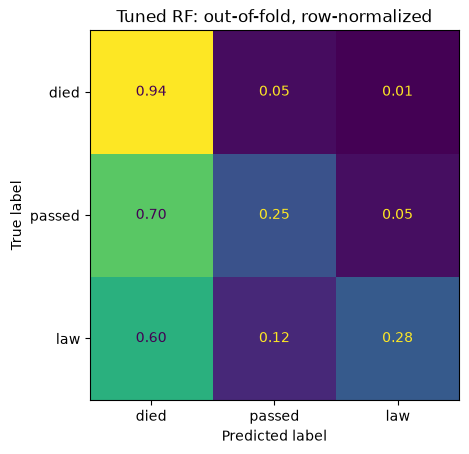

In [ ]:
best_pipe = clone(search.best_estimator_)          # unfitted copy with the winning settings

proba = cross_val_predict(best_pipe, X_train, y_train, groups=groups_train, cv=cv, method="predict_proba") # cross validation and prediction on validation fold
pred = CLASSES[proba.argmax(axis=1)] # convert probability predictions to classes by taking max predicted probability

print(classification_report(y_train, pred, labels=CLASSES, # compare true labels with the 101k out-of-fold labels to get precision, recall, and F1 per class
                            target_names=[SHORT[c] for c in CLASSES], zero_division=0))

for i, c in enumerate(CLASSES):  # y_train == c turns it into one class versus the rest. proba[:, i] is OOF probability for class c
    ap = average_precision_score(y_train == c, proba[:, i]) # rank all bills by that OOF prob and measure how well true class-c bills rise to top
    base = (y_train == c).mean() # share of bills in class c            # calc life by average precision divided by share of bills in that class
    print(f"AP {SHORT[c]:>6}: {ap:.3f}   (random = {base:.3f}, lift = {ap / base:.1f}x)")


# build confusion matrix from the out of fold labels with each row normalized
ConfusionMatrixDisplay.from_predictions(y_train, pred, labels=CLASSES, normalize="true",
    display_labels=[SHORT[c] for c in CLASSES], values_format=".2f", colorbar=False)
plt.title("Tuned RF: out-of-fold, row-normalized")

### Tuned Random Forest Out-of-Fold Diagnostics

**Setup** Best grid-search configurations: {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': 40, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5}

**Overall** Macro f1 is **0.50**, compared with 0.35 for class-balanced logistic regression and 0.35 for always predicting "died."

**Ranking (average precision)** The forest ranks rare outcomes well above chance:

    - **Became Law**: AP = 0.266 vs a 0.033 base rate (**8.1x lift**)

    - **Passed own chamber**: AP = 0.168 vs 0.053 (**3.2x Lift**)

"Passed chamber" is the hardest class. At introduction, these bills look more like bills that died than bills that became law.

**Errors** At the default decision rule (highest predicted probability), the model is conservative. It flags few bills as successes (law precision 0.36), but it misses most of them: 60% of eventual laws and 70% of chamber-passing bills are predicted to die. This is the opposite of balanced logit, which over-predicted the rare classes (law precision 0.08). When the forest does misclassify a law, it more often predicts passed (12%) than the reverse (5% of passed bills predicted as law).

 These are training-period (CV) estimates. Choosing the best of 224 configurations makes them slightly optimistic.